# Pizza Sales Analysis

An exploratory data analysis project using Python to understand pizza sales, order patterns, revenue trends, category/size contribution, and best- and low-performing pizza items.

**Dataset setup:** place the CSV file at `data/pizza_sales.csv` before running the notebook.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


Importing the dataset

In [5]:

df = pd.read_csv("C:/Users/Shreya/Desktop/ML notes/Project file/Pizza Sales.csv")


In [6]:
df.head()

,Unnamed: 0,X,id,date,time,name,size,type,price
0,1,1,2015-000001,2015-01-01,11:38:36,hawaiian,M,classic,13.25
1,2,2,2015-000002,2015-01-01,11:57:40,classic_dlx,M,classic,16.00
2,3,3,2015-000002,2015-01-01,11:57:40,mexicana,M,veggie,16.00
3,4,4,2015-000002,2015-01-01,11:57:40,thai_ckn,L,chicken,20.75
4,5,5,2015-000002,2015-01-01,11:57:40,five_cheese,L,veggie,18.50


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49574 entries, 0 to 49573
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  49574 non-null  int64  
 1   X           49574 non-null  int64  
 2   id          49574 non-null  str    
 3   date        49574 non-null  str    
 4   time        49574 non-null  str    
 5   name        49574 non-null  str    
 6   size        49574 non-null  str    
 7   type        49574 non-null  str    
 8   price       49574 non-null  float64
dtypes: float64(1), int64(2), str(6)
memory usage: 5.6 MB


In [8]:
df.isnull().sum()

Unnamed: 0    0
X             0
id            0
date          0
time          0
name          0
size          0
type          0
price         0
dtype: int64

In [9]:
df= df.drop(columns= ['Unnamed: 0','X'])

In [10]:
df['id']= df['id'].str.replace("-","").astype(int)

Metadata of Data

In [11]:
print("The metadata of the dataset:",df.shape)

The metadata of the dataset: (49574, 7)


In [12]:
print("No. of Rows in the dataset:",df.shape[0])

No. of Rows in the dataset: 49574


In [13]:
print("No. of Columns in the dataset:",df.shape[1])

No. of Columns in the dataset: 7


In [14]:
df.columns

Index(['id', 'date', 'time', 'name', 'size', 'type', 'price'], dtype='str')

In [15]:
df.describe()

,id,price
count,4.957400e+04,49574.000000
mean,2.015011e+09,16.497762
std,6.179481e+03,3.621954
min,2.015000e+09,9.750000
25%,2.015005e+09,12.750000
50%,2.015011e+09,16.500000
75%,2.015016e+09,20.250000
max,2.015021e+09,35.950000


In [16]:
df.dtypes

id         int64
date         str
time         str
name         str
size         str
type         str
price    float64
dtype: object

KPI's

In [17]:
total_revenue = df['price'].sum()
total_pizza_items = len(df)
total_orders = df['id'].nunique()
avg_order_value = total_revenue / total_orders
avg_items_per_order = total_pizza_items / total_orders

print(f'Total Revenue: ${total_revenue:,.2f}')
print(f'Total Pizza Line Items: {total_pizza_items:,}')
print(f'Total Orders: {total_orders:,}')
print(f'Average Order Value: ${avg_order_value:,.2f}')
print(f'Average Pizza Line Items per Order: {avg_items_per_order:,.2f}')


Total Revenue: $817,860.05
Total Pizza Line Items: 49,574
Total Orders: 21,350
Average Order Value: $38.31
Average Pizza Line Items per Order: 2.32


Daily Trend - Total Orders

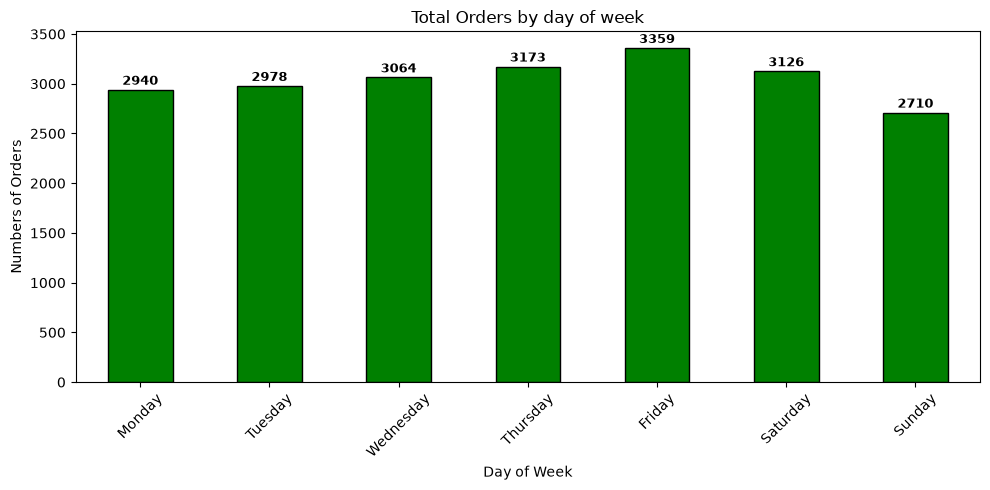

In [18]:
df['date']= pd.to_datetime(df['date'],dayfirst=True,format='mixed')
df['day_name']= df['date'].dt.day_name()

weekday_order= ['Monday',"Tuesday",'Wednesday','Thursday','Friday','Saturday','Sunday']
df['day_name']= pd.Categorical(df['day_name'],categories= weekday_order,ordered=True)
orders_by_day= df.groupby('day_name',observed=False)['id'].nunique()

ax= orders_by_day.plot(kind='bar',figsize=(10,5), color='green',edgecolor='black')

plt.title("Total Orders by day of week")
plt.xlabel("Day of Week")
plt.ylabel("Numbers of Orders")
plt.xticks(rotation=45)
for i, val in enumerate(orders_by_day):
    plt.text(i, val +20,str(val),ha='center',va='bottom',fontsize=9,fontweight='bold')
plt.tight_layout()
plt.show()

Daily Trend - Total Revenue

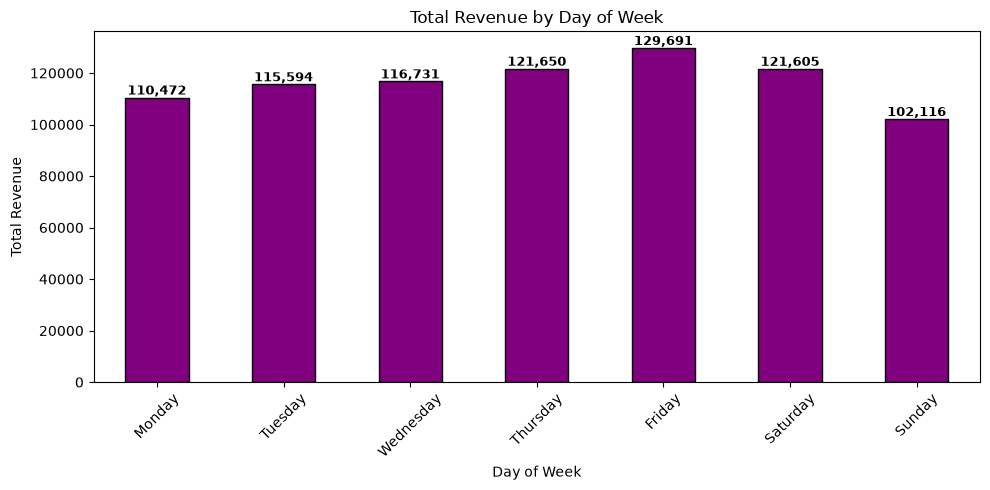

In [19]:
Revenue_by_day = df.groupby('day_name', observed=False)['price'].sum()

ax = Revenue_by_day.plot(kind='bar', figsize=(10, 5), color='purple', edgecolor='black')
plt.title('Total Revenue by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
for i, val in enumerate(Revenue_by_day):
    plt.text(i, val + 20, f'{val:,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()


Hourly Trend - Total Orders

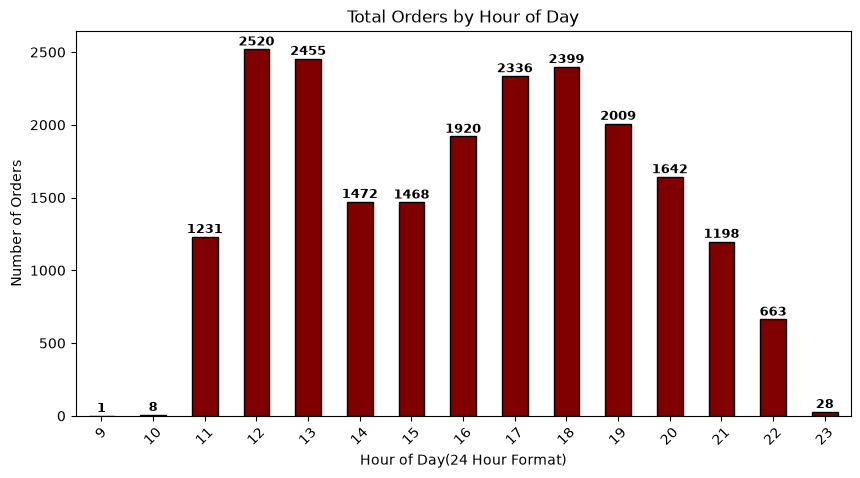

In [20]:
df['time']= pd.to_datetime(df['time'],dayfirst=True,format='%H:%M:%S')
df['order_hour']= df['time'].dt.hour


orders_by_hour= df.groupby('order_hour',observed=False)['id'].nunique()

ax= orders_by_hour.plot(kind='bar',figsize=(10,5), color='maroon',edgecolor='black')

plt.title("Total Orders by Hour of Day")
plt.xlabel("Hour of Day(24 Hour Format)")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
for i, val in enumerate(orders_by_hour):
    plt.text(i, val +5,str(val),ha='center',va='bottom',fontsize=9,fontweight='bold')
#plt.tight_layout()
plt.show()

Monthly Trend - Total Orders

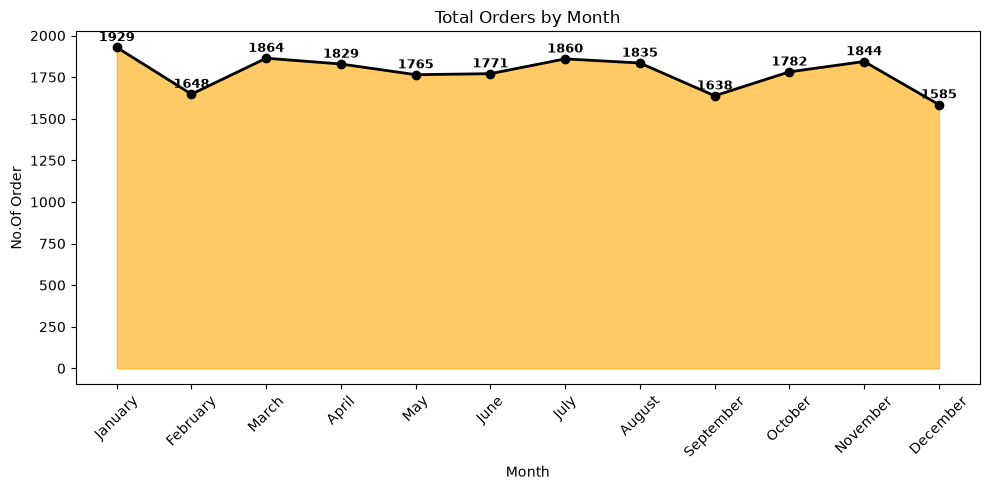

In [21]:
df['date']= pd.to_datetime(df['date'],dayfirst=True)
df['month_name']= df['date'].dt.month_name()

month_order= ['January',"February",'March','April','May','June','July','August','September','October','November','December']
df['month_name']= pd.Categorical(df['month_name'],categories= month_order,ordered=True)
Orders_by_Month= df.groupby('month_name',observed=False)['id'].nunique()

plt.figure(figsize=(10,5))
plt.fill_between(Orders_by_Month.index,Orders_by_Month.values,color='orange',alpha=0.6)
plt.plot(Orders_by_Month.index,Orders_by_Month.values,linewidth=2,marker='o',color='black')

plt.title("Total Orders by Month")
plt.xlabel("Month")
plt.ylabel("No.Of Order")
plt.xticks(rotation=45)
for i, val in enumerate(Orders_by_Month):
    plt.text(i, val +20, str(val),ha='center',va='bottom',fontsize=9,fontweight='bold')
plt.tight_layout()
plt.show()

% of Sales by Category

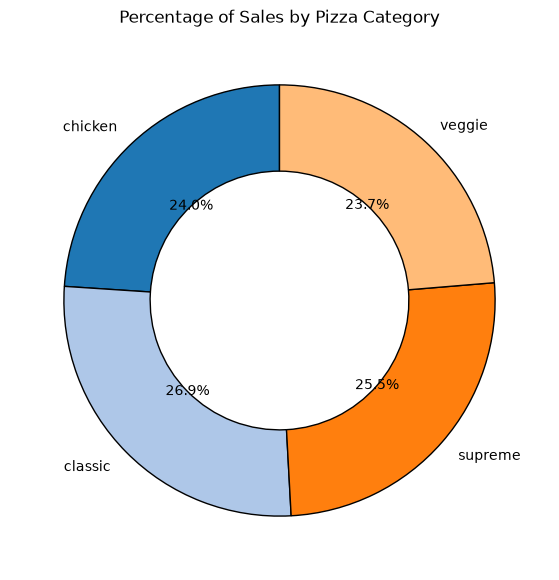

In [22]:
Category_Sales = df.groupby('type')['price'].sum()
Category_pct = Category_Sales / Category_Sales.sum()*100
plt.figure(figsize=(7,7))
colors= plt.get_cmap('tab20').colors   # nice color palette
plt.pie(Category_pct,labels=Category_pct.index, autopct='%1.1f%%',startangle=90, colors=colors,wedgeprops={'edgecolor':'black','width':0.4})
plt.title("Percentage of Sales by Pizza Category")
plt.show()

% Sales by Pizza Size & Category

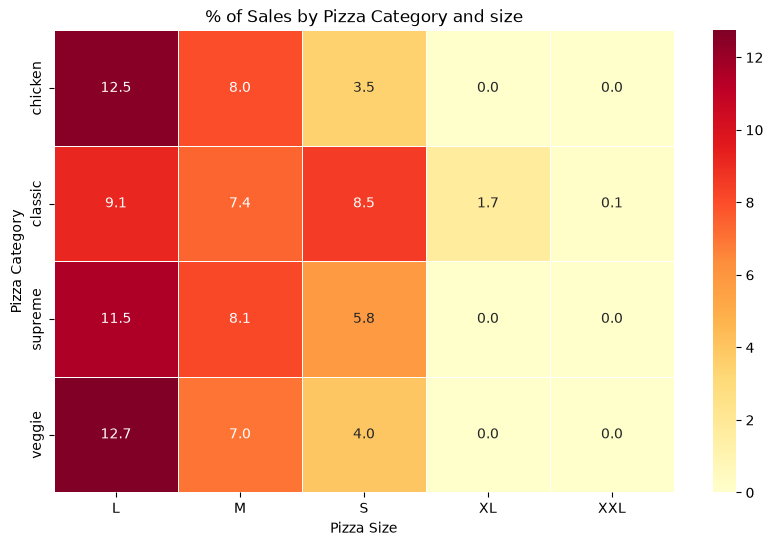

In [23]:
Sales_pivot= df.pivot_table(
index= 'type',
columns='size',
values='price',
aggfunc='sum',
fill_value=0
)

sales_pct= Sales_pivot / Sales_pivot.sum().sum()*100

plt.figure(figsize=(10,6))
sns.heatmap(sales_pct,annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.5)
plt.title("% of Sales by Pizza Category and size")
plt.ylabel("Pizza Category")
plt.xlabel("Pizza Size")
plt.show()


In [24]:
df.columns

Index(['id', 'date', 'time', 'name', 'size', 'type', 'price', 'day_name',
       'order_hour', 'month_name'],
      dtype='str')

Total Pizzas Sold by Pizza Category

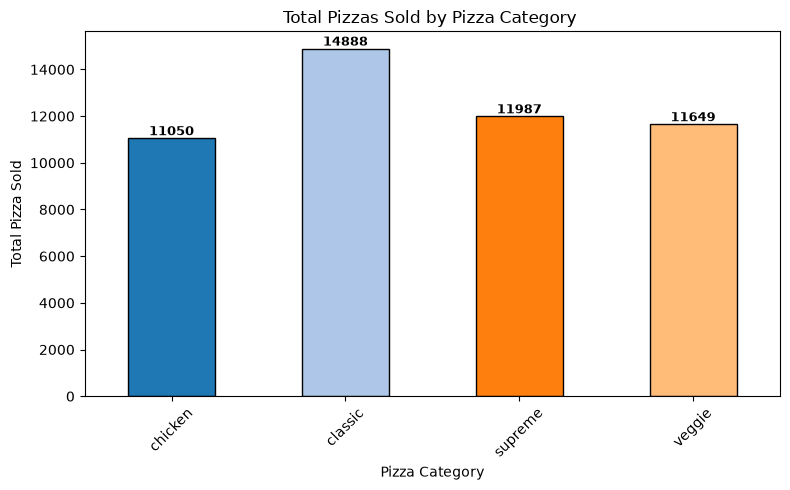

In [25]:
pizzas_by_category= df.groupby('type')['id'].count()
colors= list(plt.get_cmap('tab20').colors)
colors= colors[: len(pizzas_by_category)]

AX= pizzas_by_category.plot(kind='bar', figsize=(8,5),color=colors,edgecolor='black')

plt.title("Total Pizzas Sold by Pizza Category ")
plt.xlabel("Pizza Category")
plt.ylabel("Total Pizza Sold")
plt.xticks(rotation=45)

for i , val in enumerate(pizzas_by_category):
    plt.text(i, val +5,str(val),ha='center',va='bottom',fontsize=9,fontweight='bold')

plt.tight_layout()
plt.show()



 Top 5 Best Selling pizzas - Total Orders

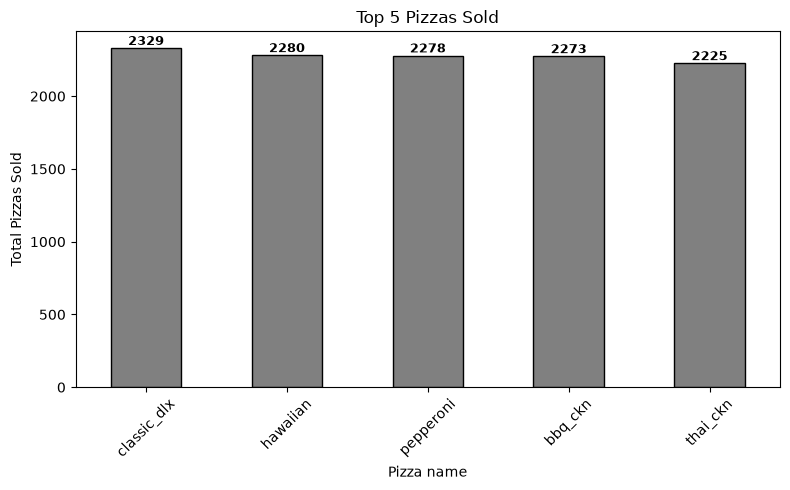

In [26]:
pizzas_by_name= df.groupby('name')['id'].nunique()
top5= pizzas_by_name.sort_values(ascending=False).head(5)
ax= top5.plot(kind='bar',figsize=(8,5),color='grey',edgecolor='black')

plt.title("Top 5 Pizzas Sold")
plt.xlabel("Pizza name")
plt.ylabel("Total Pizzas Sold")
plt.xticks(rotation=45)

for i, val in enumerate(top5):
    plt.text(i, val+2,str(val),ha='center',va='bottom',fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

 Top 5 Best Selling pizzas - Total Sales


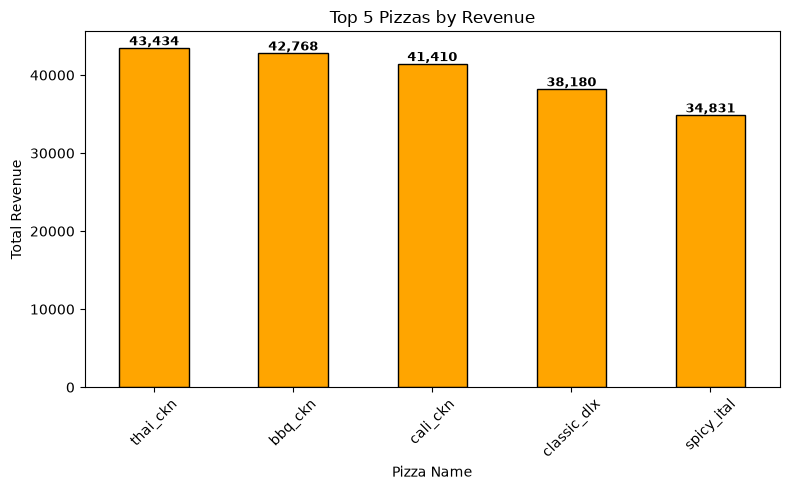

In [27]:
pizzas_by_name = df.groupby('name')['price'].sum()
top5 = pizzas_by_name.sort_values(ascending=False).head(5)
ax = top5.plot(kind='bar', figsize=(8, 5), color='orange', edgecolor='black')

plt.title('Top 5 Pizzas by Revenue')
plt.xlabel('Pizza Name')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
for i, val in enumerate(top5):
    plt.text(i, val + 2, f'{val:,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()


Bottom 5 Selling Pizzas- Total Sales

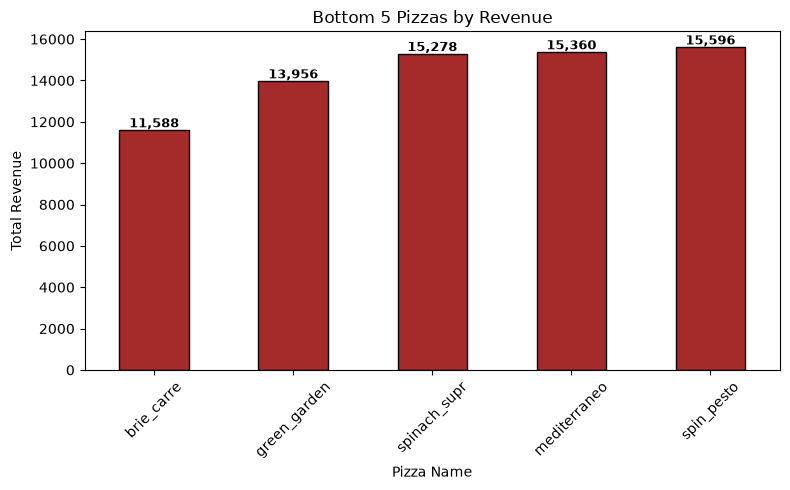

In [28]:
pizzas_by_name = df.groupby('name')['price'].sum()
bottom5 = pizzas_by_name.sort_values(ascending=True).head(5)

ax = bottom5.plot(kind='bar', figsize=(8, 5), color='brown', edgecolor='black')
plt.title('Bottom 5 Pizzas by Revenue')
plt.xlabel('Pizza Name')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
for i, val in enumerate(bottom5):
    plt.text(i, val + 2, f'{val:,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()
